# 08 — ConvNeXt-Tiny dan evaluasi ensemble
Ensemble empat model sebelumnya mencapai accuracy holdout **88,2252%** dan macro-F1 **0,881401**. Skor leaderboard submission itu belum dilaporkan saat eksperimen ini dimulai. Kelas terlemah tetap scientific_report, presentation, dan form.

Hipotesis: ConvNeXt dapat menghasilkan kesalahan yang berbeda dari EfficientNet dan ResNet sehingga membantu ensemble. Inisialisasi menggunakan [ConvNeXt-Tiny ImageNet-1K V1 resmi Torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.convnext_tiny.html), tanpa checkpoint yang dilatih pada dataset kompetisi ini. Semua label supervised berasal dari training split yang sama.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/convnext_diversity'
SELECTED = ROOT / 'reports/convnext_selection'
display(pd.read_json(ROOT / 'reports/leaderboard_history.json'))
display(pd.read_csv(ROOT / 'reports/resnet_highres_selection/classification_report.csv', index_col=0).iloc[:16].sort_values('f1-score').head())

,reported_on,run_name,submission,submission_sha256,score,score_source,leaderboard_partition,metric_name
0,2026-10-27,baseline_cnn,submissions/submission_baseline.csv,5fd9913aedf081fdb66e9823eb28e36e6146162113f3d1...,0.67294,Reported by user in chat,unspecified,unverified
1,2026-10-28,efficientnet_improved,submissions/submission_improved.csv,2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80...,0.85236,Reported by user in chat,unspecified,unverified
2,2026-10-28,highres_selection,submissions/submission_highres_selected.csv,9a2231e16ba635ae4f99aa8f74fe8ed5efd46853e856fc...,0.86491,Reported by user in chat,unspecified,unverified


,precision,recall,f1-score,support
scientific_report,0.738717,0.760391,0.749398,409.0
presentation,0.736715,0.772152,0.754017,395.0
form,0.758530,0.774799,0.766578,373.0
questionnaire,0.849741,0.854167,0.851948,384.0
budget,0.858974,0.861183,0.860077,389.0


## Preprocessing dan training
Cache letterbox 224×224 mempertahankan rasio halaman dan padding putih. Grayscale direplikasi ke tiga kanal dan dinormalisasi ImageNet. Training memakai kontras dan affine ringan seperti eksperimen sebelumnya; validasi serta inference deterministik. Tidak ada OCR, fitur ID/filename, flip, atau lookup label test.

Head diganti menjadi 16 kelas; semua layer di-fine-tune dengan AdamW LR 0,0001, weight decay 0,05, cosine schedule 10 epoch, label smoothing 0,05, batch 24, dan patience 4. Stochastic depth menggunakan default ConvNeXt-Tiny torchvision (0,1). Konfigurasi optimizer berbeda dari backbone sebelumnya, sehingga ini bukan ablation arsitektur murni.

Reproduksi: `python -m scripts.train --config configs/convnext_diversity.json --device cuda`. Bobot pertama diunduh dari PyTorch, diverifikasi hash-nya, lalu disimpan pada checkpoint/pretrained yang diabaikan Git.

In [2]:
display(json.loads((ROOT / 'configs/convnext_diversity.json').read_text()))
display(json.loads((RUN / 'run.json').read_text()))
display(pd.read_csv(RUN / 'history.csv'))
display(Markdown((RUN / 'interpretation.md').read_text(encoding='utf-8')))

{'run_name': 'convnext_diversity',
 'model': 'convnext_tiny',
 'pretrained': True,
 'image_size': 224,
 'epochs': 10,
 'batch_size': 24,
 'learning_rate': 0.0001,
 'weight_decay': 0.05,
 'label_smoothing': 0.05,
 'patience': 4,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 2,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy',
 'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}}

{'config': {'run_name': 'convnext_diversity',
  'model': 'convnext_tiny',
  'pretrained': True,
  'image_size': 224,
  'epochs': 10,
  'batch_size': 24,
  'learning_rate': 0.0001,
  'weight_decay': 0.05,
  'label_smoothing': 0.05,
  'patience': 4,
  'seed': 42,
  'validation_fraction': 0.2,
  'workers': 2,
  'threads': 4,
  'amp': True,
  'selection_metric': 'accuracy',
  'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}},
 'device': 'cuda',
 'versions': {'torch': '2.11.0+cu128',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.7',
  'torchvision': '0.26.0+cu128'},
 'initialization': None,
 'device_name': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'train_rows': 25607,
 'validation_rows': 6395,
 'metadata_digest': '7d3d83196e1e9ae8aad8d980fbe579e496da5999e2e36f2622f0eeb4d08b179e',
 'parameter_count': 27832432}

,epoch,train_loss,val_loss,accuracy,macro_f1,learning_rate,seconds
0,1,1.199032,0.741636,0.782643,0.775501,0.000100,222.709386
1,2,0.810471,0.570532,0.833776,0.834996,0.000098,148.279446
2,3,0.658506,0.561565,0.844566,0.845177,0.000090,138.491949
3,4,0.545440,0.559029,0.847224,0.847770,0.000079,148.027247
4,5,0.466564,0.530952,0.857389,0.855043,0.000065,138.960317
5,6,0.406414,0.552506,0.859109,0.858256,0.000050,138.444053
6,7,0.376717,0.551896,0.862549,0.861821,0.000035,140.195936
7,8,0.355184,0.543476,0.866145,0.864891,0.000021,137.842254
8,9,0.343696,0.547524,0.868804,0.867754,0.000010,137.313043
9,10,0.338993,0.547032,0.868491,0.867347,0.000002,135.641306


### Eksperimen `convnext_diversity`

| Metrik | Hasil |
| --- | ---: |
| Accuracy validasi | 86.8804% |
| Macro-F1 validasi | 0.867754 |
| Majority-class baseline accuracy | 6.5676% |
| Halaman training / validasi | 25,607 / 6,395 |
| Epoch terbaik / epoch dijalankan | 9 / 10 |
| Waktu loop training + validasi | 24.8 menit |
| Perangkat | cuda |
| Skor leaderboard | Belum tersedia |

Kelas dengan F1 tertinggi: `email` (0.968), `handwritten` (0.932), `file_folder` (0.926).
Kelas dengan F1 terendah: `scientific_report` (0.722), `form` (0.743), `presentation` (0.750).

Kesalahan terbanyak (aktual → prediksi): `scientific_report` → `presentation` (33 halaman); `presentation` → `scientific_report` (27 halaman); `scientific_report` → `scientific_publication` (23 halaman).

Accuracy validasi per epoch berkisar 78.26%–86.88%. Checkpoint dipilih berdasarkan metrik holdout pada konfigurasi. Training loss memakai label smoothing sedangkan validation loss tidak, sehingga nilai absolut keduanya tidak sepenuhnya sebanding.

Hasil ini mengukur satu holdout dengan pemisahan duplikat persis. Holdout juga dipakai untuk memilih checkpoint, sehingga skor dapat optimistis setelah tuning. Skor tersebut bukan public/private leaderboard.

Model `convnext_tiny` menggunakan resolusi 224×224. Kemiripan layout adalah hipotesis penyebab kesalahan, bukan kesimpulan kausal dari confusion matrix. Periksa kelas lemah dan contoh halaman sebelum menentukan eksperimen berikutnya.

Artefak: [metrics](metrics.json), [history](history.csv), [split](split.csv), dan [interpretasi lengkap](interpretation.md).

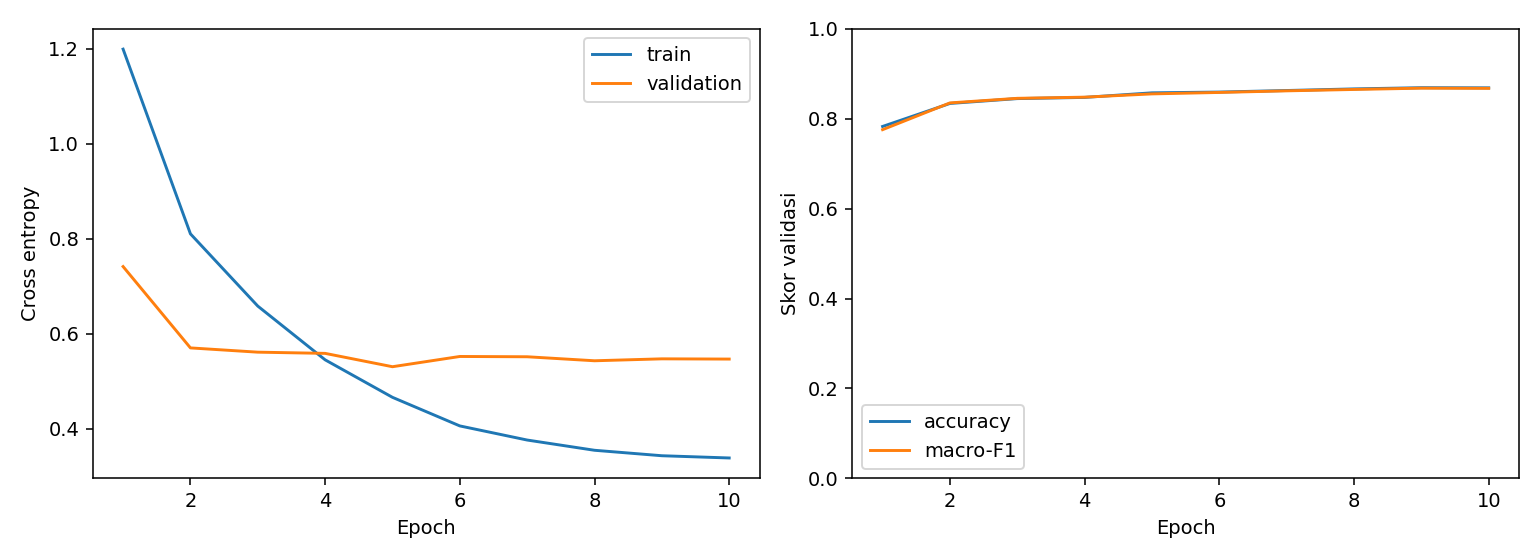

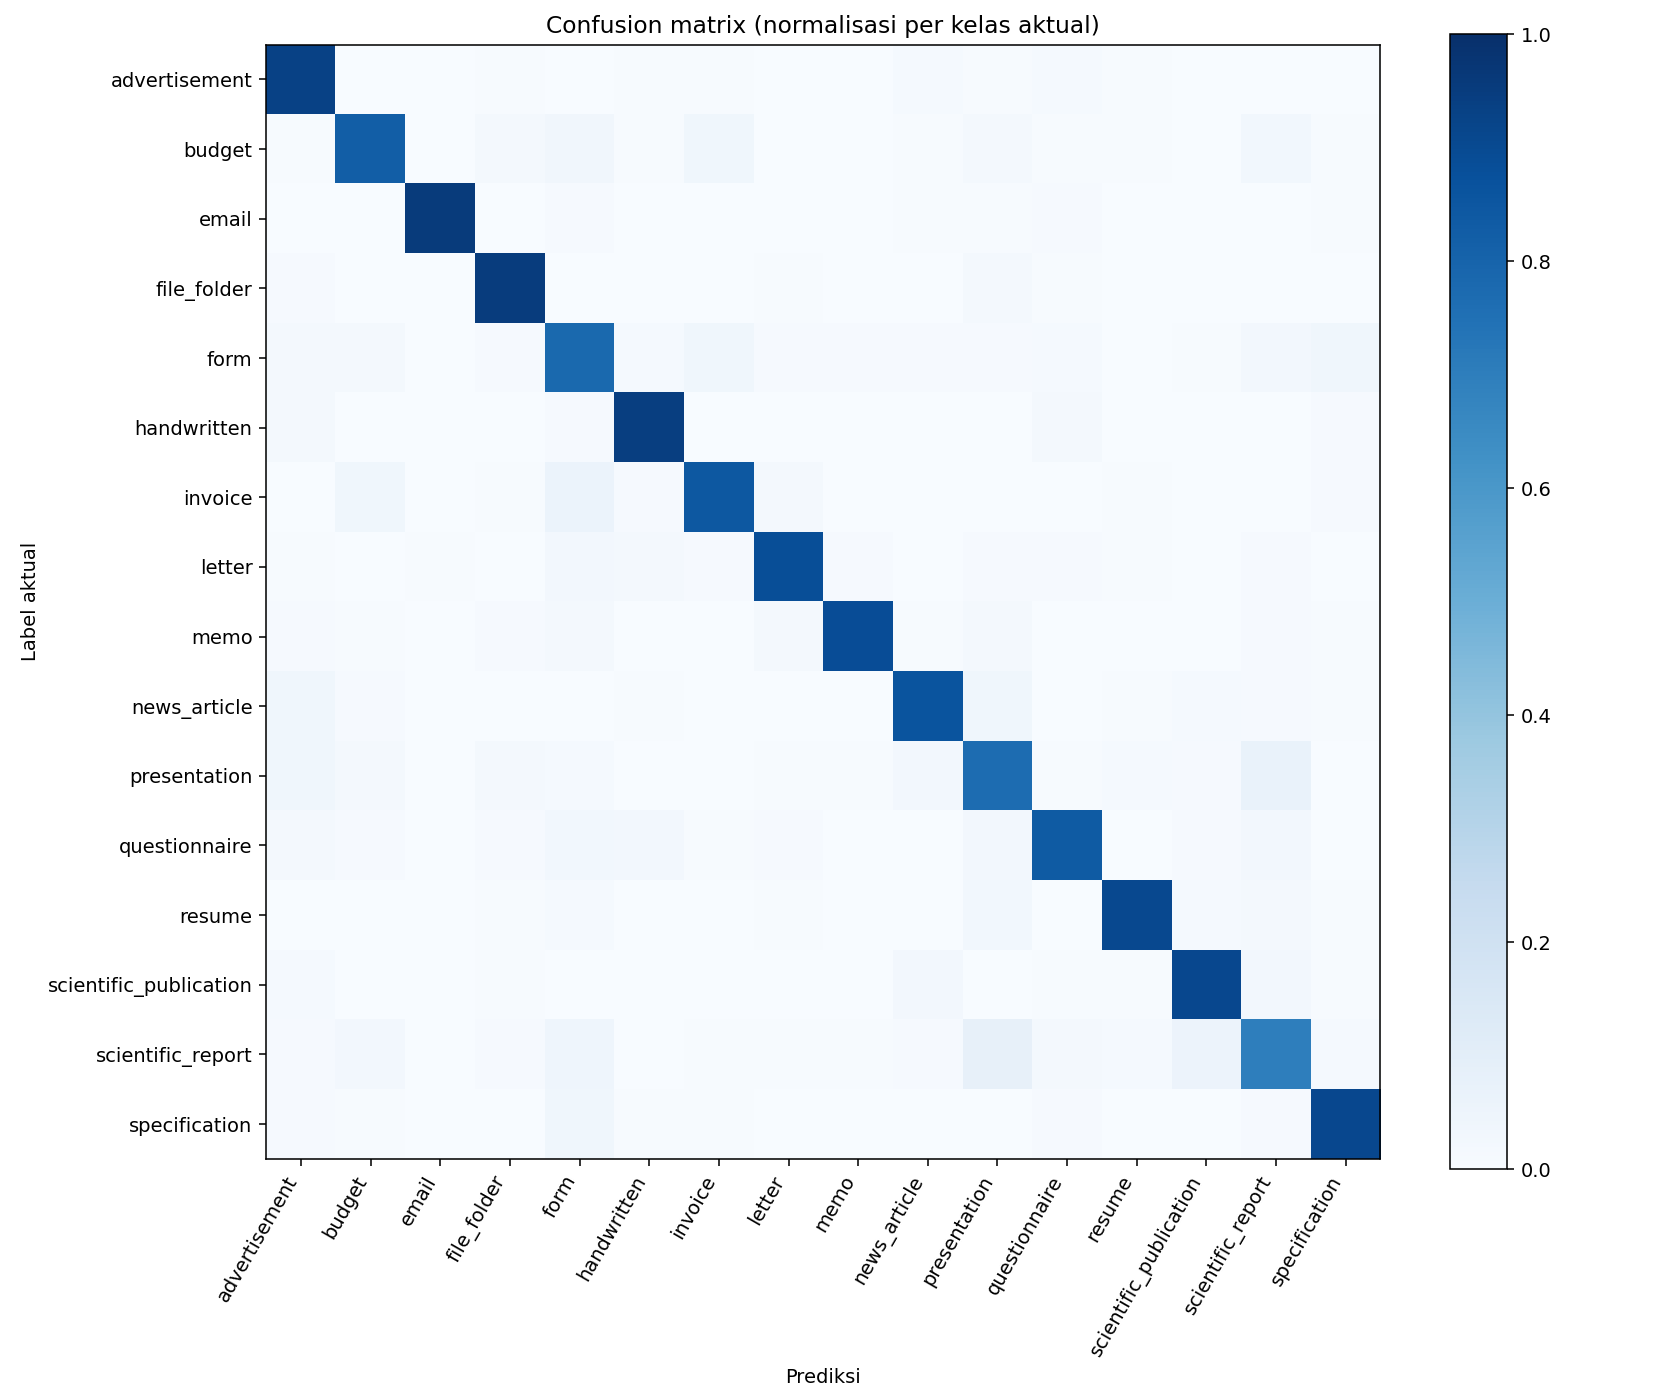

,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_31349,train/letter/0060056676.tif,letter,7,8,memo,0.975510
1,train_08928,train/file_folder/2049475699.tif,file_folder,3,10,presentation,0.973149
2,train_20289,train/memo/2029236668.tif,memo,8,7,letter,0.970876
3,train_22707,train/news_article/2025823276_2025823277.tif,news_article,9,10,presentation,0.970274
4,train_20057,train/invoice/506372665_506372700.tif,invoice,6,7,letter,0.970081
5,train_26090,train/form/2030722680_2030722682.tif,form,4,14,scientific_report,0.969016
6,train_19521,train/news_article/1005119085.tif,news_article,9,10,presentation,0.968616
7,train_10049,train/scientific_publication/2050934356.tif,scientific_publication,13,14,scientific_report,0.966221
8,train_22936,train/scientific_report/2028896921-a_202889692...,scientific_report,14,13,scientific_publication,0.966133
9,train_15924,train/form/0011800189.tif,form,4,6,invoice,0.965879


In [3]:
display(Image(filename=str(RUN / 'learning_curves.png')))
display(Image(filename=str(RUN / 'confusion_matrix.png')))
display(pd.read_csv(RUN / 'confident_errors.csv').head(10))

## Kandidat berbobot tetap
Urutan komponen: EfficientNet 224, EfficientNet 320, ResNet 224, ResNet 320, ConvNeXt 224. Empat kandidat ditetapkan sebelum training: ensemble lama, ConvNeXt tunggal, kombinasi dengan total bobot 1/3 untuk setiap keluarga arsitektur, serta kombinasi 50:50 ensemble lama dengan ConvNeXt.

Pilih accuracy holdout tertinggi; seri memilih kandidat paling awal. Tidak ada grid search bobot atau bobot per kelas. Pipeline memeriksa split lengkap, ID, label mapping, fingerprint metadata, dan identitas checkpoint pada cache probabilitas. Arsip validasi EfficientNet lama belum menyimpan hash checkpoint; keterbatasan ini dicatat pada laporan komponen.

In [4]:
selection = json.loads((SELECTED / 'selection.json').read_text())
display(json.loads((ROOT / 'configs/convnext_selection.json').read_text()))
display(pd.read_csv(SELECTED / 'candidates.csv'))
display(Markdown((SELECTED / 'interpretation.md').read_text(encoding='utf-8')))
display(pd.read_csv(SELECTED / 'class_comparison.csv').sort_values('delta_f1'))
display(pd.read_csv(SELECTED / 'confident_errors.csv').head(10))

{'experiment': 'convnext_selection',
 'runs': ['efficientnet_improved',
  'efficientnet_highres',
  'resnet_diversity',
  'resnet_highres',
  'convnext_diversity'],
 'candidates': [{'variant': 'previous_four_model_blend',
   'weights': [0.25, 0.25, 0.25, 0.25, 0.0]},
  {'variant': 'convnext_single', 'weights': [0.0, 0.0, 0.0, 0.0, 1.0]},
  {'variant': 'equal_architecture_blend',
   'weights': [0.16666666666666666,
    0.16666666666666666,
    0.16666666666666666,
    0.16666666666666666,
    0.3333333333333333]},
  {'variant': 'half_convnext_blend',
   'weights': [0.125, 0.125, 0.125, 0.125, 0.5]}],
 'selection_rule': 'Highest holdout accuracy; ties prefer the first listed candidate',
 'submission': 'submissions/submission_convnext_selected.csv'}

,variant,weights,accuracy,macro_f1
0,previous_four_model_blend,"[0.25, 0.25, 0.25, 0.25, 0.0]",0.882252,0.881401
1,convnext_single,"[0.0, 0.0, 0.0, 0.0, 1.0]",0.868804,0.867754
2,equal_architecture_blend,"[0.16666666666666666, 0.16666666666666666, 0.1...",0.883815,0.883172
3,half_convnext_blend,"[0.125, 0.125, 0.125, 0.125, 0.5]",0.880219,0.879404


# Pemilihan convnext_selection

Kandidat terpilih: **equal_architecture_blend**, bobot [0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.3333333333333333].

| Kandidat | Accuracy validasi | Macro-F1 |
| --- | ---: | ---: |
| previous_four_model_blend | 88.2252% | 0.881401 |
| convnext_single | 86.8804% | 0.867754 |
| equal_architecture_blend | 88.3815% | 0.883172 |
| half_convnext_blend | 88.0219% | 0.879404 |

Perubahan terhadap kandidat pertama: +0.16 poin persentase accuracy pada 6,395 halaman validasi yang sama.
Memperbaiki 88 kesalahan dan menambah 78 kesalahan. F1 meningkat pada 9 dari 16 kelas.

Kelas terlemah: scientific_report (0.754), presentation (0.765), form (0.774).

Manfaat komponen baru dinilai melalui hasil kandidat tunggal dan gabungan. Eksperimen ini tidak memisahkan efek arsitektur, resolusi, inisialisasi, dan jadwal training secara kausal.

Holdout yang sama sudah digunakan untuk memilih checkpoint dan kandidat. Tidak ada evaluasi CV independen setelah tuning. Tidak ada label test atau lookup duplikat test yang dipakai. Skor leaderboard baru harus dicatat setelah submission.

File: `submissions/submission_convnext_selected.csv` (7,994 baris). Hash dan rincian komponen tersedia di `selection.json`.

,class_name,previous_f1,selected_f1,delta_f1
0,advertisement,0.905983,0.896635,-0.009348
15,specification,0.916442,0.908602,-0.007840
9,news_article,0.908136,0.900783,-0.007353
5,handwritten,0.946067,0.942761,-0.003306
8,memo,0.930403,0.927607,-0.002796
2,email,0.977661,0.974967,-0.002694
12,resume,0.928571,0.926267,-0.002304
1,budget,0.860077,0.860825,0.000748
13,scientific_publication,0.922894,0.923810,0.000915
3,file_folder,0.929642,0.931792,0.002149


,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_17516,train/scientific_report/2082647017_7026.tif,scientific_report,14,10,presentation,0.967631
1,train_25513,train/invoice/508729058.tif,invoice,6,4,form,0.967477
2,train_29353,train/resume/2025684886.tif,resume,12,10,presentation,0.963596
3,train_05863,train/scientific_report/2057124602_4603.tif,scientific_report,14,15,specification,0.963586
4,train_10006,train/presentation/2028987355_2028987357.tif,presentation,10,14,scientific_report,0.963426
5,train_16971,train/handwritten/509132718+-2718.tif,handwritten,5,0,advertisement,0.962442
6,train_17566,train/scientific_report/2053453117.tif,scientific_report,14,15,specification,0.962036
7,train_11150,train/memo/94158557.tif,memo,8,4,form,0.961912
8,train_03399,train/scientific_report/81560070_0086.tif,scientific_report,14,10,presentation,0.960892
9,train_10965,train/form/0000977190.tif,form,4,1,budget,0.957812


## Submission dan batas kesimpulan
Holdout sudah dipakai berulang untuk memilih checkpoint dan kandidat. Skor lokal ini belum menjadi estimasi independen setelah tuning; hasil leaderboard perlu dicatat secara terpisah. Jika kandidat baru tidak membaik, selector mempertahankan ensemble sebelumnya. Tidak ada label test yang digunakan untuk pemilihan.

Seluruh submission terdahulu dipertahankan. Bobot pretrained dan checkpoint dapat melebihi 100 MB sehingga wajib tetap berada pada direktori yang diabaikan Git, bukan diunggah sebagai source.

In [5]:
from scripts.predict import validate_submission
from scripts.preprocess import read_metadata, data_directory
_, test, sample = read_metadata(data_directory())
path = ROOT / selection['submission']
submission = pd.read_csv(path)
validate_submission(submission, sample)
assert len(submission) == len(test)
assert hashlib.sha256(path.read_bytes()).hexdigest() == selection['submission_sha256']
for name in ('highres_selection', 'diversity_selection', 'resnet_highres_selection'):
    previous = json.loads((ROOT / 'reports' / name / 'selection.json').read_text())
    assert hashlib.sha256((ROOT / previous['submission']).read_bytes()).hexdigest() == previous['submission_sha256']
print(f'Validated {len(submission)} rows; variant={selection["selected"]["variant"]}')
display(submission.head())

Validated 7994 rows; variant=equal_architecture_blend


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
